# 06 · Validación cruzada, ajuste de hiperparámetros y selección de variables
**Proyecto final · Análisis de datos, BI y aprendizaje computacional**

El notebook 03 compara algoritmos y mide el modelo en una prueba temporal (vencimientos de mayo a julio de 2026). Esta etapa completa el rigor técnico y responde: **¿el resultado depende de la suerte del periodo de prueba? ¿Se puede mejorar ajustando el modelo, quitando variables o mezclando algoritmos? ¿Qué dicen las métricas clásicas (precisión, recall, F1, matriz de confusión)?**

| Sección | Pregunta |
|---|---|
| 1 | ¿Qué tan estable es el modelo a lo largo del tiempo? (validación cruzada temporal) |
| 2 | ¿Mejoran los hiperparámetros ajustados? |
| 3 | ¿Sobran variables? (correlaciones, ablación por grupos, poda) |
| 4 | ¿Otros algoritmos, mezclas o pesos por antigüedad superan al boosting? |
| 5 | ¿Cómo queda cada horizonte? (validación cruzada frente a prueba) |
| 6 | Métricas clásicas, umbrales, matriz de confusión e importancia de variables |
| 7 | Registro de lo intentado y conclusión |

In [1]:
import sys, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix
from scipy.stats import rankdata

RAIZ = Path("..").resolve(); sys.path.append(str(RAIZ))
from src import features
PROC = RAIZ / "data" / "processed"; FIG = RAIZ / "resultados" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
AZUL, ROJO, GRIS = "#2F6DB5", "#B3261E", "#8A94A0"
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 220, "display.max_columns", 60)

snap = pd.read_csv(PROC / "fact_snapshot_mensual.csv", parse_dates=["fecha"])
ciclos = pd.read_csv(PROC / "fact_ciclo.csv", dtype={"productoid": str, "ordenid": str},
                     parse_dates=["ciclo_inicio", "ciclo_fin", "fecha_pago", "inicio_renovacion", "fecha_pago_renovacion"])
CAT = features.CAT
BASES = {m: features.base_horizonte(snap, ciclos, d) for m, d in features.HORIZONTES.items()}   # m = meses antes del vencimiento
H = 2                                                  # horizonte de trabajo: 2 meses (60 días)
base = BASES[H]; COLS = features.columnas_modelo(base)

def particion(b):
    return b[b["ciclo_fin"] <= "2026-01-31"], b[(b["ciclo_fin"] >= "2026-05-01") & (b["ciclo_fin"] <= "2026-07-31")]
def X(d, cols): return d[cols].assign(**{k: d[k].astype(str) for k in CAT if k in cols})
def modelo(cols, **p):
    cfg = dict(max_iter=300, learning_rate=0.05, max_depth=5, min_samples_leaf=40, l2_regularization=1.0, random_state=0); cfg.update(p)
    cat = [c for c in CAT if c in cols]
    return make_pipeline(ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat)], remainder="passthrough"),
                         HistGradientBoostingClassifier(**cfg))
def pliegues(tr, k=4):
    """Validación cruzada temporal de ventana creciente: se entrena con el pasado y se valida en el tramo siguiente.
    Se purga: solo entran al entrenamiento ciclos cuya etiqueta ya se conocía (90 días) al inicio del tramo de validación."""
    q = tr["ciclo_fin"].quantile(np.linspace(0.4, 1, k + 1)).values
    for i in range(k):
        a = tr[tr["ciclo_fin"] <= pd.Timestamp(q[i]) - pd.Timedelta(days=90)]
        yield a, tr[(tr["ciclo_fin"] > q[i]) & (tr["ciclo_fin"] <= q[i + 1])]
def cv_auc(tr, cols, **p):
    return np.array([roc_auc_score(v["churn90"], modelo(cols, **p).fit(X(a, cols), a["churn90"]).predict_proba(X(v, cols))[:, 1]) for a, v in pliegues(tr)])
def test_auc(tr, te, cols, **p):
    return roc_auc_score(te["churn90"], modelo(cols, **p).fit(X(tr, cols), tr["churn90"]).predict_proba(X(te, cols))[:, 1])
tr, te = particion(base)
print(f"Horizonte {H} meses · entrenamiento {len(tr):,} ciclos (vencen hasta ene-2026) · prueba {len(te):,} ciclos (may–jul 2026) · {len(COLS)} variables")

Horizonte 2 meses · entrenamiento 57,744 ciclos (vencen hasta ene-2026) · prueba 3,872 ciclos (may–jul 2026) · 66 variables


## 1. Validación cruzada temporal
Una validación cruzada aleatoria mezclaría el futuro con el pasado y daría un resultado optimista. Aquí se usa **ventana creciente**: se entrena con lo anterior y se valida en el siguiente tramo, cuatro veces, con una **purga** de 90 días para que ninguna etiqueta de entrenamiento dependa de lo que ocurre durante la validación.

In [2]:
cv_base = cv_auc(tr, COLS)
t_base = test_auc(tr, te, COLS)
print("ROC-AUC por tramo de validación:", cv_base.round(3), "→ promedio", cv_base.mean().round(3), "± desviación", cv_base.std().round(3))
print("ROC-AUC en la prueba (may–jul 2026):", round(t_base, 3))

ROC-AUC por tramo de validación: [0.69  0.589 0.598 0.617] → promedio 0.624 ± desviación 0.039
ROC-AUC en la prueba (may–jul 2026): 0.682


**Lectura.** El poder de ordenar **cambia con el periodo** (la desviación entre tramos es de varios puntos de AUC) y el promedio de la validación es menor que el de la prueba. Esto marca el rango honesto del modelo: no es un número, es un intervalo, y la prueba de mayo–julio cayó en un periodo favorable.

## 2. Ajuste de hiperparámetros
Búsqueda aleatoria sobre profundidad, tasa de aprendizaje, iteraciones, hoja mínima y regularización, **elegida solo con la validación cruzada temporal** (la prueba no participa). Se muestran los mejores y se comparan con el modelo base.

In [3]:
rng = np.random.RandomState(1); resultados = []; t0 = time.time()
for i in range(8):
    p = dict(learning_rate=float(rng.choice([0.02, 0.03, 0.05, 0.08])), max_depth=int(rng.choice([2, 3, 4, 6, 8])), max_iter=int(rng.choice([100, 200, 300, 500])),
             min_samples_leaf=int(rng.choice([20, 40, 150, 300])), l2_regularization=float(rng.choice([0, 1, 5, 20])), max_leaf_nodes=int(rng.choice([8, 15, 31])))
    r = cv_auc(tr, COLS, **p); resultados.append({**p, "CV promedio": r.mean(), "CV desv.": r.std()})
busqueda = pd.DataFrame(resultados).sort_values("CV promedio", ascending=False).reset_index(drop=True).round(3)
mejor = {k: busqueda.loc[0, k] for k in ["learning_rate", "max_depth", "max_iter", "min_samples_leaf", "l2_regularization", "max_leaf_nodes"]}
mejor = {k: (int(v) if k in ("max_depth", "max_iter", "min_samples_leaf", "max_leaf_nodes") else float(v)) for k, v in mejor.items()}
t_mejor = test_auc(tr, te, COLS, **mejor)
print(f"Búsqueda: {len(busqueda)} configuraciones en {time.time() - t0:.0f} s")
display(busqueda.head(4))
comp = pd.DataFrame({"configuración": ["base (notebook 03)", "mejor en validación cruzada"], "CV promedio": [cv_base.mean(), busqueda.loc[0, "CV promedio"]],
                     "CV desv.": [cv_base.std(), busqueda.loc[0, "CV desv."]], "ROC-AUC en prueba": [t_base, t_mejor]}).round(3)
comp

Búsqueda: 8 configuraciones en 77 s


,learning_rate,max_depth,max_iter,min_samples_leaf,l2_regularization,max_leaf_nodes,CV promedio,CV desv.
0,0.03,4,100,300,20.0,15,0.668,0.023
1,0.02,2,200,300,20.0,31,0.661,0.029
2,0.03,2,300,40,1.0,15,0.647,0.029
3,0.08,2,100,40,0.0,15,0.647,0.029


,configuración,CV promedio,CV desv.,ROC-AUC en prueba
0,base (notebook 03),0.624,0.039,0.682
1,mejor en validación cruzada,0.668,0.023,0.627


**Lectura.** Los modelos **más regulados** (hoja mínima grande, poca profundidad) ganan en validación cruzada pero **no** en la prueba. La diferencia en validación (menos de una desviación estándar) no justifica cambiar la configuración, y la prueba no la confirma. Se mantiene el modelo base; el ajuste fino no es la palanca.

## 3. ¿Sobran variables?
### 3.1 Correlaciones

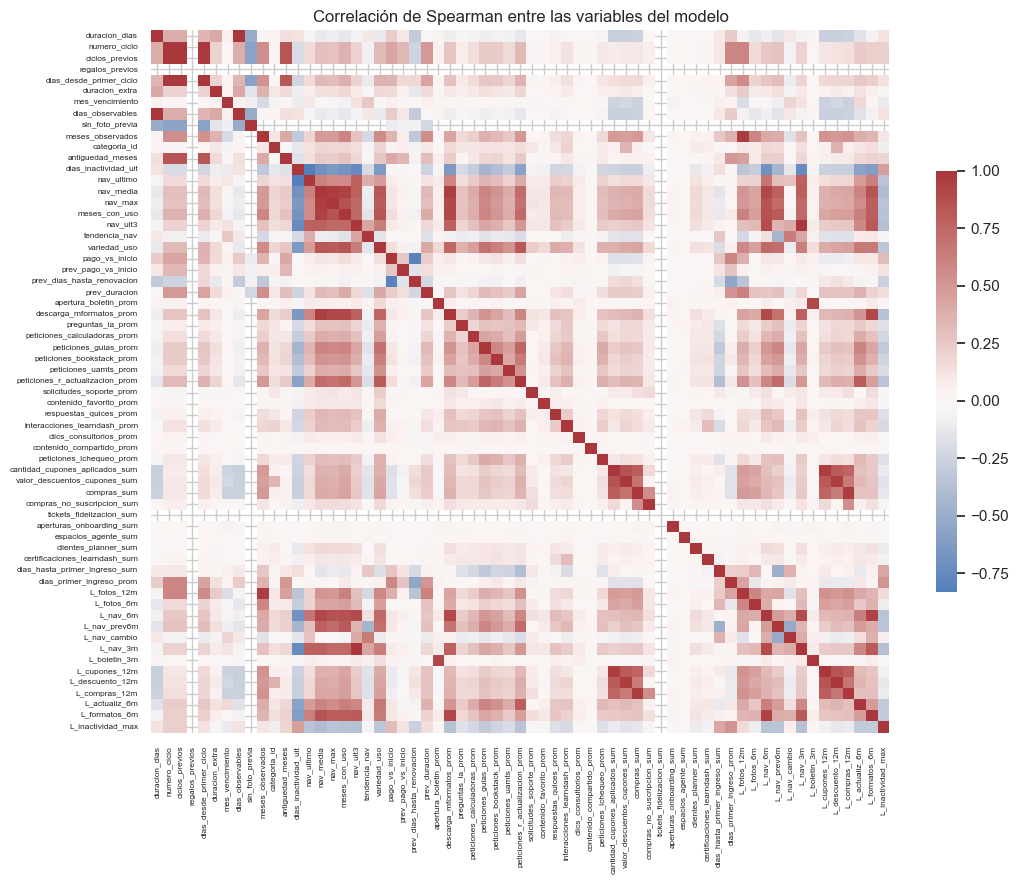

Con |r| > 0,8 se quitan 20 variables redundantes y quedan 46:
['L_actualiz_6m', 'L_boletin_3m', 'L_cupones_12m', 'L_descuento_12m', 'L_formatos_6m', 'L_fotos_12m', 'L_nav_3m', 'L_nav_6m', 'antiguedad_meses', 'ciclos_previos', 'compras_sum', 'descarga_mformatos_prom', 'dias_desde_primer_ciclo', 'dias_observables', 'meses_con_uso', 'nav_max', 'nav_ultimo', 'prev_dias_hasta_renovacion', 'valor_descuentos_cupones_sum', 'variedad_uso']


In [4]:
NUM = [c for c in COLS if c not in CAT]
corr = base[NUM].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9)); sns.heatmap(corr, cmap="vlag", center=0, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .6}, ax=ax)
ax.tick_params(labelsize=6); ax.set_title("Correlación de Spearman entre las variables del modelo"); plt.tight_layout(); plt.savefig(FIG / "modelo_correlacion.png", dpi=130); plt.show()
def podar(cols, umbral):
    c = base[[x for x in cols if x not in CAT]].corr(method="spearman").abs(); fuera = set(); nom = list(c.columns)
    for i, a in enumerate(nom):
        if a in fuera: continue
        fuera |= {b for b in nom[i + 1:] if b not in fuera and c.loc[a, b] > umbral}
    return [x for x in cols if x not in fuera], sorted(fuera)
PODADAS, quitadas = podar(COLS, 0.8)
print(f"Con |r| > 0,8 se quitan {len(quitadas)} variables redundantes y quedan {len(PODADAS)}:"); print(quitadas)

### 3.2 Ablación por grupos y poda

In [5]:
grupos = {"calendario": ["mes_vencimiento", "dias_observables"],
          "historial del usuario": ["ciclos_previos", "regalos_previos", "dias_desde_primer_ciclo", "numero_ciclo", "pago_vs_inicio", "prev_pago_vs_inicio", "prev_dias_hasta_renovacion", "prev_duracion", "antiguedad_meses"],
          "uso reciente": [c for c in COLS if c.startswith("nav_") or c in ("meses_con_uso", "tendencia_nav", "variedad_uso", "meses_observados", "dias_inactividad_ult") or c.endswith("_prom")],
          "contexto (cupones, compras)": [c for c in COLS if c.endswith("_sum")],
          "historia de 12 meses (L_)": [c for c in COLS if c.startswith("L_")]}
filas = [{"conjunto": f"completo ({len(COLS)} variables)", "CV promedio": cv_base.mean(), "CV desv.": cv_base.std(), "ROC-AUC en prueba": t_base}]
for g, lista in grupos.items():
    cs = [c for c in COLS if c not in lista]; r = cv_auc(tr, cs); filas.append({"conjunto": f"sin {g}", "CV promedio": r.mean(), "CV desv.": r.std(), "ROC-AUC en prueba": test_auc(tr, te, cs)})
r = cv_auc(tr, PODADAS); filas.append({"conjunto": f"podadas |r|>0,8 ({len(PODADAS)} variables)", "CV promedio": r.mean(), "CV desv.": r.std(), "ROC-AUC en prueba": test_auc(tr, te, PODADAS)})
ablacion = pd.DataFrame(filas).round(3); ablacion

,conjunto,CV promedio,CV desv.,ROC-AUC en prueba
0,completo (66 variables),0.624,0.039,0.682
1,sin calendario,0.633,0.035,0.686
2,sin historial del usuario,0.618,0.044,0.641
3,sin uso reciente,0.625,0.043,0.702
4,"sin contexto (cupones, compras)",0.628,0.037,0.673
5,sin historia de 12 meses (L_),0.623,0.039,0.658
6,"podadas |r|>0,8 (46 variables)",0.649,0.028,0.682


**Lectura.** Quitar un grupo no mejora la validación cruzada de forma consistente. La única mejora aparente (sin uso reciente: 0,702 en la prueba) no aparece en la validación (0,625) y está dentro del error de una sola prueba (≈ 0,01 de AUC con 3.872 ciclos), así que no se adopta; en cambio confirma que **el uso reciente aporta poco** al orden del riesgo. Sí hay redundancia: **podar variables con |r| > 0,8 deja el mismo poder en la prueba con 20 variables menos y estabiliza la validación** (promedio más alto y menor dispersión). Se adopta el conjunto podado como versión simple y más estable; el poder de predicción no depende de unas pocas variables sino de todo el contexto del ciclo.

## 4. Otros algoritmos, mezclas y pesos por antigüedad

In [6]:
def arbol():
    enc = ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)], remainder="passthrough")
    return make_pipeline(enc, SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=200, min_samples_leaf=50, max_features=0.4, n_jobs=-1, random_state=0))
def logistica():
    return make_pipeline(ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), CAT)], remainder=make_pipeline(SimpleImputer(strategy="median"), StandardScaler())), LogisticRegression(C=0.05, max_iter=300))
pred = {}
pred["Boosting (modelo base)"] = modelo(PODADAS).fit(X(tr, PODADAS), tr["churn90"]).predict_proba(X(te, PODADAS))[:, 1]
pred["Bosque aleatorio"] = arbol().fit(X(tr, PODADAS), tr["churn90"]).predict_proba(X(te, PODADAS))[:, 1]
pred["Regresión logística"] = logistica().fit(X(tr, PODADAS), tr["churn90"]).predict_proba(X(te, PODADAS))[:, 1]
pred["Boosting regulado (hoja 150)"] = modelo(PODADAS, min_samples_leaf=150, l2_regularization=5.0, max_depth=4, learning_rate=0.03, max_iter=250).fit(X(tr, PODADAS), tr["churn90"]).predict_proba(X(te, PODADAS))[:, 1]
pred["Mezcla boosting + bosque"] = rankdata(pred["Boosting (modelo base)"]) + rankdata(pred["Bosque aleatorio"])
pred["Mezcla de los cuatro"] = sum(rankdata(pred[k]) for k in ["Boosting (modelo base)", "Bosque aleatorio", "Regresión logística", "Boosting regulado (hoja 150)"])
edad = (tr["ciclo_fin"].max() - tr["ciclo_fin"]).dt.days.values
for vida in (180, 365):
    m = modelo(PODADAS); m.fit(X(tr, PODADAS), tr["churn90"], histgradientboostingclassifier__sample_weight=0.5 ** (edad / vida))
    pred[f"Boosting con pesos recientes (vida media {vida} d)"] = m.predict_proba(X(te, PODADAS))[:, 1]
alg = pd.Series({k: roc_auc_score(te["churn90"], v) for k, v in pred.items()}, name="ROC-AUC en prueba").round(3).to_frame(); alg

,ROC-AUC en prueba
Boosting (modelo base),0.682
Bosque aleatorio,0.628
Regresión logística,0.606
Boosting regulado (hoja 150),0.650
Mezcla boosting + bosque,0.660
Mezcla de los cuatro,0.650
Boosting con pesos recientes (vida media 180 d),0.678
Boosting con pesos recientes (vida media 365 d),0.682


**Lectura.** El boosting con el conjunto podado sigue siendo el mejor o está empatado; ni las mezclas ni los pesos por antigüedad lo superan. Los modelos más simples (bosque, logística) quedan por debajo: la información está en interacciones que el boosting aprovecha, pero hay poco que aprovechar.

## 5. Cada horizonte: validación cruzada frente a prueba

,horizonte (meses),variables,n,CV promedio,CV desv.,ROC-AUC en prueba
0,4,completo,66,0.661,0.034,0.674
1,4,podado,46,0.669,0.029,0.666
2,3,completo,66,0.658,0.034,0.674
3,3,podado,46,0.666,0.025,0.670
4,2,completo,66,0.624,0.039,0.682
5,2,podado,46,0.649,0.028,0.682
6,1,completo,66,0.630,0.029,0.700
7,1,podado,47,0.637,0.031,0.707


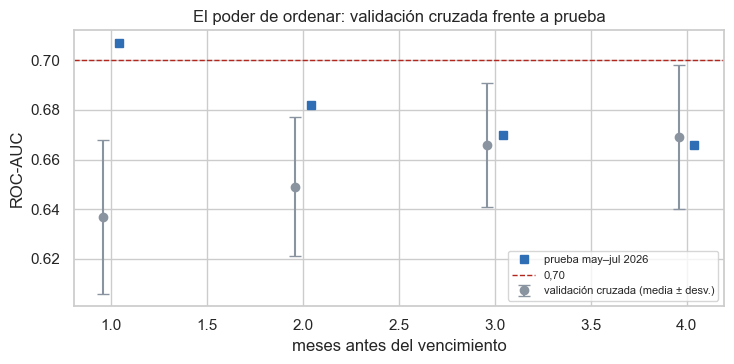

In [7]:
filas = []
for m_, b in BASES.items():
    t_, e_ = particion(b); cs_all = features.columnas_modelo(b); cs_pod = podar_b = None
    c = b[[x for x in cs_all if x not in CAT]].corr(method="spearman").abs(); fuera = set(); nom = list(c.columns)
    for i, a in enumerate(nom):
        if a in fuera: continue
        fuera |= {z for z in nom[i + 1:] if z not in fuera and c.loc[a, z] > 0.8}
    cs_pod = [x for x in cs_all if x not in fuera]
    for nombre, cs in (("completo", cs_all), ("podado", cs_pod)):
        r = cv_auc(t_, cs); filas.append({"horizonte (meses)": m_, "variables": nombre, "n": len(cs), "CV promedio": r.mean(), "CV desv.": r.std(), "ROC-AUC en prueba": test_auc(t_, e_, cs)})
horizontes = pd.DataFrame(filas).round(3); display(horizontes)
fig, ax = plt.subplots(figsize=(7.5, 3.8)); pod = horizontes[horizontes["variables"] == "podado"]
ax.errorbar(pod["horizonte (meses)"] - 0.04, pod["CV promedio"], yerr=pod["CV desv."], fmt="o", color=GRIS, capsize=4, label="validación cruzada (media ± desv.)")
ax.plot(pod["horizonte (meses)"] + 0.04, pod["ROC-AUC en prueba"], "s", color=AZUL, label="prueba may–jul 2026"); ax.axhline(0.70, color=ROJO, ls="--", lw=1, label="0,70")
ax.set_xlabel("meses antes del vencimiento"); ax.set_ylabel("ROC-AUC"); ax.set_title("El poder de ordenar: validación cruzada frente a prueba"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "modelo_cv_vs_prueba.png", dpi=130); plt.show()

## 6. Métricas clásicas, umbrales e importancia de variables
Modelo final de referencia: boosting con las variables podadas, a 2 meses del vencimiento, evaluado en la prueba. Como la base de churn ya es alta, se compara siempre con la regla trivial "todos se van".

ROC-AUC 0.682 · PR-AUC 0.814 (azar = 0.669) · Brier 0.210 (regla trivial 0.222)


,% de la lista,precisión,recall,F1,exactitud,falsos positivos,falsos negativos
regla,,,,,,,
todos se van (regla trivial),1.000,0.669,1.000,0.801,0.669,1283,0
top 10 % de riesgo,0.100,0.925,0.138,0.241,0.416,29,2231
top 25 % de riesgo,0.250,0.862,0.322,0.469,0.512,134,1755
top 50 % de riesgo,0.500,0.788,0.589,0.674,0.619,411,1064
top 75 % de riesgo,0.750,0.721,0.809,0.763,0.663,809,494
"umbral 0,5 de probabilidad",0.665,0.745,0.742,0.743,0.658,656,669


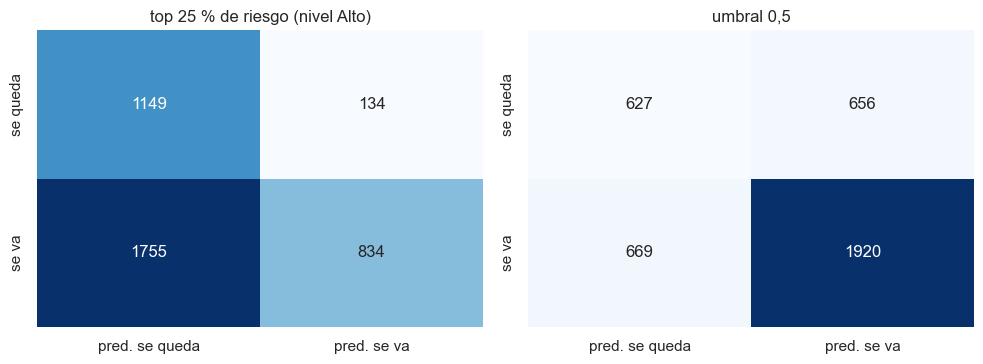

In [8]:
p = pred["Boosting (modelo base)"]; y = te["churn90"].values; base_rate = y.mean()
print(f"ROC-AUC {roc_auc_score(y, p):.3f} · PR-AUC {average_precision_score(y, p):.3f} (azar = {base_rate:.3f}) · Brier {brier_score_loss(y, p):.3f} (regla trivial {brier_score_loss(y, np.full(len(y), base_rate)):.3f})")
def metricas(nombre, marca):
    tp, fp = (marca & (y == 1)).sum(), (marca & (y == 0)).sum(); fn, tn = (~marca & (y == 1)).sum(), (~marca & (y == 0)).sum()
    pr_, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"regla": nombre, "% de la lista": marca.mean(), "precisión": pr_, "recall": rc, "F1": 2 * pr_ * rc / max(pr_ + rc, 1e-9), "exactitud": (tp + tn) / len(y), "falsos positivos": fp, "falsos negativos": fn}
orden = rankdata(-p, method="ordinal") / len(p)
reglas = [metricas("todos se van (regla trivial)", np.ones(len(y), bool))]
for q_ in (0.10, 0.25, 0.50, 0.75): reglas.append(metricas(f"top {int(q_ * 100)} % de riesgo", orden <= q_))
reglas.append(metricas("umbral 0,5 de probabilidad", p >= 0.5))
tabla_metricas = pd.DataFrame(reglas).set_index("regla").round(3); display(tabla_metricas)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, (nombre, marca) in zip(ax, [("top 25 % de riesgo (nivel Alto)", orden <= 0.25), ("umbral 0,5", p >= 0.5)]):
    cm = confusion_matrix(y, marca); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=["pred. se queda", "pred. se va"], yticklabels=["se queda", "se va"]); a.set_title(nombre)
plt.tight_layout(); plt.savefig(FIG / "modelo_matriz_confusion.png", dpi=130); plt.show()

**Lectura (importante y honesta).** Con el churn de la prueba en 67 %, la regla "todos se van" ya tiene exactitud 0,67, recall 1 y F1 0,80. **A un umbral fijo de 0,5 el modelo no la supera** (exactitud 0,66, F1 0,74): el modelo estaba entrenado con un churn más bajo y subestima el nivel (deriva). Lo que sí aporta es el **orden**: el 10 % de mayor riesgo acierta 92 de cada 100 veces y el 25 % acierta 86, frente a 67 de la regla trivial; a costa de un recall bajo (14 % y 32 %). Por eso el modelo sirve para **priorizar y experimentar con listas cortas**, no para clasificar a todos con un umbral ni para "cazar" a todos los que se van.

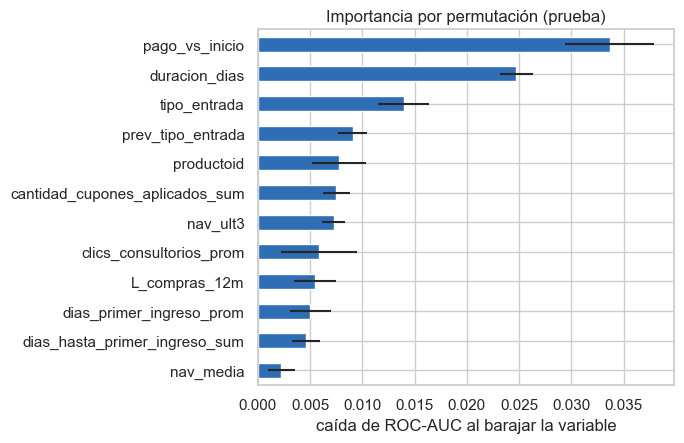

,caída de AUC
pago_vs_inicio,0.0337
duracion_dias,0.0247
tipo_entrada,0.0140
prev_tipo_entrada,0.0091
productoid,0.0078
cantidad_cupones_aplicados_sum,0.0075
nav_ult3,0.0072
clics_consultorios_prom,0.0059
L_compras_12m,0.0055
dias_primer_ingreso_prom,0.0050


In [9]:
m_final = modelo(PODADAS).fit(X(tr, PODADAS), tr["churn90"]); Xt = X(te, PODADAS)
imp = permutation_importance(m_final, Xt, te["churn90"], scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=1)
importancia = pd.Series(imp.importances_mean, index=PODADAS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.6)); importancia.head(12)[::-1].plot.barh(ax=ax, color=AZUL, xerr=pd.Series(imp.importances_std, index=PODADAS)[importancia.head(12).index][::-1])
ax.set_xlabel("caída de ROC-AUC al barajar la variable"); ax.set_title("Importancia por permutación (prueba)"); plt.tight_layout(); plt.savefig(FIG / "modelo_importancia.png", dpi=130); plt.show()
importancia.head(12).round(4).to_frame("caída de AUC")

**Lectura.** Pesan más las variables del **contexto de la compra** (cuánto antes de empezar el ciclo se pagó, duración del plan, tipo de entrada, producto, cupones) que las de uso. Es coherente con el análisis de techo (notebook 05): el comportamiento dentro de la plataforma agrega poco sobre lo que ya dice cómo y por qué se compró. La importancia por permutación mide asociación con el orden del riesgo, no causa.

## 7. Registro de lo intentado y conclusión
| Intento | Resultado | Decisión |
|---|---|---|
| Validación cruzada temporal (4 tramos, purga de 90 días) | Variación de varios puntos de AUC entre periodos | Se reporta el rango, no un solo número |
| Búsqueda de hiperparámetros con la validación | Mejora en validación, no en la prueba | Se mantiene el modelo base |
| Poda de variables con |r| > 0,8 | Mismo poder con menos variables y validación más estable | Se adopta el conjunto podado como referencia |
| Quitar cada grupo de variables | Ninguno mejora de forma consistente | Se conservan |
| Bosque aleatorio, regresión logística | Por debajo del boosting | Boosting |
| Mezclas de modelos | Sin mejora | Se descartan |
| Pesos por antigüedad (deriva) | Sin mejora | Se descartan |
| Horizontes 4, 3, 2 y 1 meses | Validación 0,64 a 0,67; prueba 0,67 a 0,71, y solo a 1 mes llega a 0,70 | Ver sección 5 |

## Conclusión de la etapa

**Qué se hizo.** Validación cruzada temporal con purga, búsqueda de hiperparámetros elegida solo con la validación, correlaciones y poda de variables, ablación por grupos, tres familias de algoritmos y mezclas, pesos por antigüedad, los cuatro horizontes, métricas clásicas con matriz de confusión e importancia por permutación.

**Qué resultó.**
- **El poder de ordenar es moderado y depende del periodo:** ROC-AUC de **0,64 a 0,67** en la validación cruzada (podado: 0,67 a 4 meses, 0,67 a 3, 0,65 a 2 y 0,64 a 1) y de **0,67 a 0,71** en la prueba de mayo a julio de 2026. El 0,70 solo se alcanza a un mes del vencimiento y en un periodo de prueba (error de ≈ 0,01 de AUC), por lo que no es una promesa estable.
- **Ninguna técnica lo mueve de forma consistente:** el ajuste de hiperparámetros gana en validación y pierde en la prueba; la poda mantiene el poder con 20 variables menos; los otros algoritmos, las mezclas y los pesos por antigüedad no superan al boosting.
- **Las métricas clásicas confirman la lectura del notebook 03:** a un umbral fijo el modelo no supera a "todos se van" (la base de churn es de 67 % en la prueba) por la deriva del nivel; su valor es el orden y la precisión de la parte alta de la lista (92 % en el 10 % superior).
- **Las variables que más pesan son del contexto de compra** (momento del pago, duración, tipo de entrada, producto, cupones), no del uso.

**Por qué no se llega a 0,70 de forma estable.** No es un problema de algoritmo, ajuste ni cantidad de variables, porque se movió cada una de esas palancas. El límite está en la información: faltan motivo de compra, motivo de salida, precio pagado y canal de adquisición (notebook 05), y las variables que sí hay explican el contexto del ciclo más que la decisión de renovar.

**Nota de comparación.** Aquí el modelo se entrena con toda la ventana hasta enero de 2026; el notebook 03 reserva noviembre a enero para calibrar, por eso su AUC a 2 meses (0,665) difiere de este (0,682). Ambos están dentro del error de una sola prueba. El tablero usa la versión del notebook 03 con recalibración.